In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing

In [2]:
data = sm.datasets.co2.load_pandas().data
series = data["co2"].resample("MS").mean()
series = series.fillna(series.bfill())

In [3]:
data.head()

,co2
1958-03-29,316.1
1958-04-05,317.3
1958-04-12,317.6
1958-04-19,317.5
1958-04-26,316.4


In [4]:
train = series.iloc[:-12]
test = series.iloc[-12:]

In [5]:
# Moving Average forecast (window = 12)
ma_forecast = pd.Series(train.rolling(window=12).mean().iloc[-1],
index=test.index)

In [6]:
# Simple Exponential Smoothing
ses = SimpleExpSmoothing(train, initialization_method="estimated").fit()
ses_forecast = ses.forecast(12)

In [7]:
# Holt-Winters Exponential Smoothing (trend + seasonality)
hw = ExponentialSmoothing(train, trend="add", seasonal="add",
seasonal_periods=12).fit()
hw_forecast = hw.forecast(12)

In [8]:
forecasts = {"Moving Average": ma_forecast,
"Simple Exp. Smoothing": ses_forecast,
"Holt-Winters": hw_forecast}

In [10]:
for name, fc in forecasts.items():
    print(name, "RMSE:", np.sqrt(np.mean((test - fc) ** 2)))

Moving Average RMSE: 2.3678675063815735
Simple Exp. Smoothing RMSE: 2.3187680936375474
Holt-Winters RMSE: 0.25430613444034994


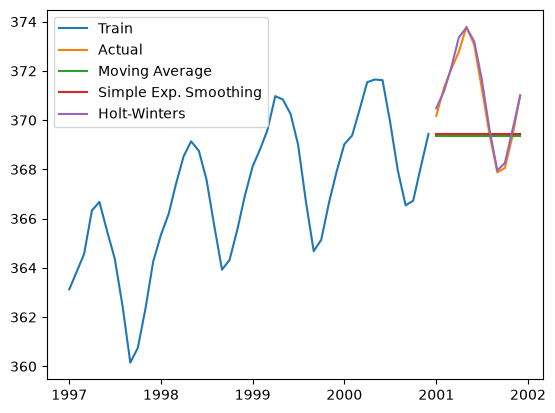

In [11]:
plt.plot(train.iloc[-48:], label="Train")
plt.plot(test, label="Actual")
for name, fc in forecasts.items():
    plt.plot(fc, label=name)
plt.legend()
plt.show()